# Comparing generative models on a 2D density

`probjax.nn` provides several generative families behind the same
`fit` / `as_dist` interface:

- **`EDM`** learns a denoiser with the EDM noise schedule and samples with a
  probability-flow ODE (or an SDE),
- **`LinearFlow`** learns a velocity field with flow matching and samples by
  integrating an ODE,
- **`LinearMeanFlow`** learns the *average* velocity between two times, which
  allows sampling in one or two steps.

This notebook trains all three on the same checkerboard density at two model
scales, then compares sample quality with the energy distance and measures
training and sampling time. It is a small controlled demonstration, not a
benchmark.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx

from probjax.nn import EDM, LinearFlow, LinearMeanFlow, TimeMLP

from data import CheckerboardGenerator

print("backend:", jax.default_backend())
print("devices:", jax.devices())

backend: gpu
devices: [CudaDevice(id=0)]


## Data and metric

The checkerboard is a standard 2D test density: a 3x3 grid with alternating
occupied cells and sharp boundaries. We use disjoint training and test sets.

The **energy distance** is zero for identical distributions and grows as the
sample distribution differs from the data. It needs no density model, so the
same metric applies to diffusion and flow models.

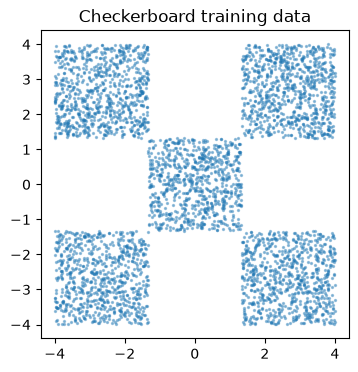

In [2]:
generator = CheckerboardGenerator(grid_size=3, scale=4.0)
train_data = generator.generate(4096, key=jax.random.key(0))
test_data = generator.generate(4096, key=jax.random.key(1))


def _pairwise(a, b):
    return jnp.sqrt(((a[:, None, :] - b[None, :, :]) ** 2).sum(-1) + 1e-12)


def energy_distance(samples, reference):
    return (
        2 * _pairwise(samples, reference).mean()
        - _pairwise(samples, samples).mean()
        - _pairwise(reference, reference).mean()
    )


plt.figure(figsize=(4, 4))
plt.scatter(train_data[:, 0], train_data[:, 1], s=2, alpha=0.4)
plt.title("Checkerboard training data")
plt.gca().set_aspect("equal")
plt.show()

## Model scales

Two scales keep the study honest without making it heavy: a small network
trained for 3k steps, and a larger network trained for 12k steps. All models
share the same `TimeMLP` backbone; only the generative objective and sampler
differ.

`LinearMeanFlow` samples with two grid points (one jump) because that is its
main selling point; the other models use a 32-step solver.

In [3]:
SCALES = {
    "small": {"hidden_dim": 64, "depth": 2, "num_steps": 3_000},
    "large": {"hidden_dim": 192, "depth": 4, "num_steps": 12_000},
}

MODELS = {
    "EDM": {
        "cls": EDM,
        "kwargs": {"num_steps": 32},
        "sample": {"mode": "ode"},
    },
    "LinearFlow": {
        "cls": LinearFlow,
        "kwargs": {},
        "sample": {"num_steps": 32},
    },
    "LinearMeanFlow": {
        "cls": LinearMeanFlow,
        "kwargs": {},
        "sample": {"num_steps": 2},
    },
}

## Train and sample

Training and sampling are timed separately; `block_until_ready` makes the GPU
timings meaningful. Each run uses a fresh network and the same data.

In [4]:
def run_model(name, spec, scale_name, scale, seed=0):
    net = TimeMLP(
        2,
        hidden_dim=scale["hidden_dim"],
        depth=scale["depth"],
        rngs=nnx.Rngs(seed),
    )
    model = spec["cls"](net, event_spec=2, **spec["kwargs"])

    start = time.perf_counter()
    losses = model.fit(
        jax.random.key(seed + 1),
        train_data,
        num_steps=scale["num_steps"],
        batch_size=256,
    ).losses
    jax.block_until_ready(losses)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    samples = model.as_dist((2,), **spec["sample"]).sample(
        jax.random.key(seed + 2), (2048,)
    )
    jax.block_until_ready(samples)
    sample_seconds = time.perf_counter() - start

    return {
        "model": model,
        "losses": losses,
        "samples": samples,
        "train_seconds": train_seconds,
        "sample_seconds": sample_seconds,
        "energy_distance": float(energy_distance(samples, test_data)),
    }


results = {}
for name, spec in MODELS.items():
    for scale_name, scale in SCALES.items():
        print(f"training {name} ({scale_name}, {scale['num_steps']} steps) ...")
        result = run_model(name, spec, scale_name, scale)
        results[(name, scale_name)] = result
        print(
            f"  energy distance {result['energy_distance']:.4f} | "
            f"train {result['train_seconds']:.1f}s | "
            f"sample {result['sample_seconds']:.2f}s"
        )

training EDM (small, 3000 steps) ...


  energy distance 0.0189 | train 4.2s | sample 1.47s
training EDM (large, 12000 steps) ...


  energy distance 0.0222 | train 13.8s | sample 1.15s
training LinearFlow (small, 3000 steps) ...


  energy distance 0.0256 | train 3.5s | sample 0.84s
training LinearFlow (large, 12000 steps) ...


  energy distance 0.0180 | train 13.4s | sample 0.96s
training LinearMeanFlow (small, 3000 steps) ...


  energy distance 0.7525 | train 5.7s | sample 0.37s
training LinearMeanFlow (large, 12000 steps) ...


  energy distance 0.8670 | train 18.7s | sample 0.45s


At this budget `EDM` and `LinearFlow` are already close to the data, and the
larger `LinearFlow` improves slightly; the `EDM` difference is within
single-seed noise. The one-jump `LinearMeanFlow` sampler is by far the fastest
but clearly worse here — it catches up by about 8-16 steps in the next section.

In [5]:
header = f"{'model':16s} {'scale':6s} {'steps':>6s} {'train s':>8s} {'sample s':>9s} {'energy':>8s}"
print(header)
for (name, scale_name), result in results.items():
    scale = SCALES[scale_name]
    print(
        f"{name:16s} {scale_name:6s} {scale['num_steps']:6d} "
        f"{result['train_seconds']:8.1f} {result['sample_seconds']:9.3f} "
        f"{result['energy_distance']:8.4f}"
    )

model            scale   steps  train s  sample s   energy
EDM              small    3000      4.2     1.473   0.0189
EDM              large   12000     13.8     1.148   0.0222
LinearFlow       small    3000      3.5     0.844   0.0256
LinearFlow       large   12000     13.4     0.958   0.0180
LinearMeanFlow   small    3000      5.7     0.367   0.7525
LinearMeanFlow   large   12000     18.7     0.450   0.8670


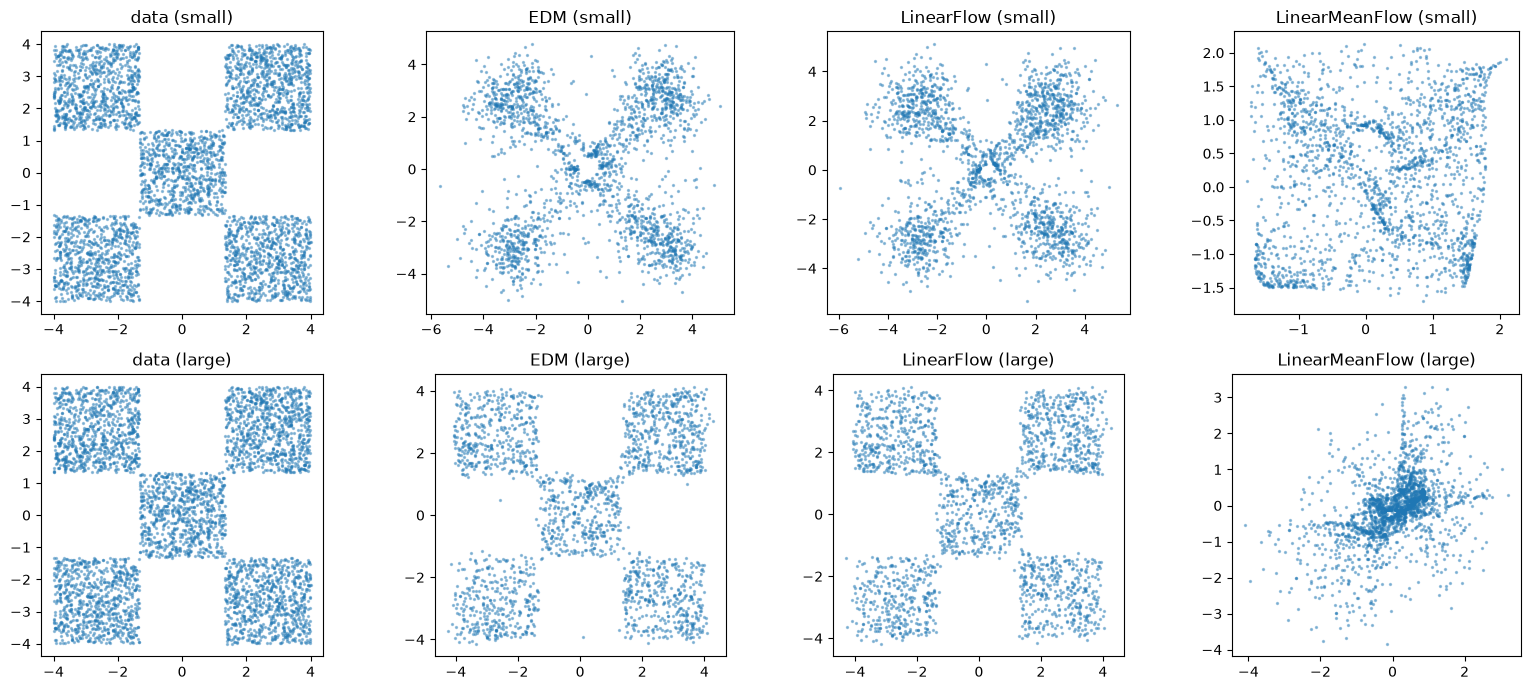

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for row, scale_name in zip(axes, SCALES):
    row[0].scatter(train_data[:, 0], train_data[:, 1], s=2, alpha=0.4)
    row[0].set_title(f"data ({scale_name})")
    for ax, name in zip(row[1:], MODELS):
        samples = results[(name, scale_name)]["samples"]
        ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.4)
        ax.set_title(f"{name} ({scale_name})")
    for ax in row:
        ax.set_aspect("equal")
plt.tight_layout()
plt.show()

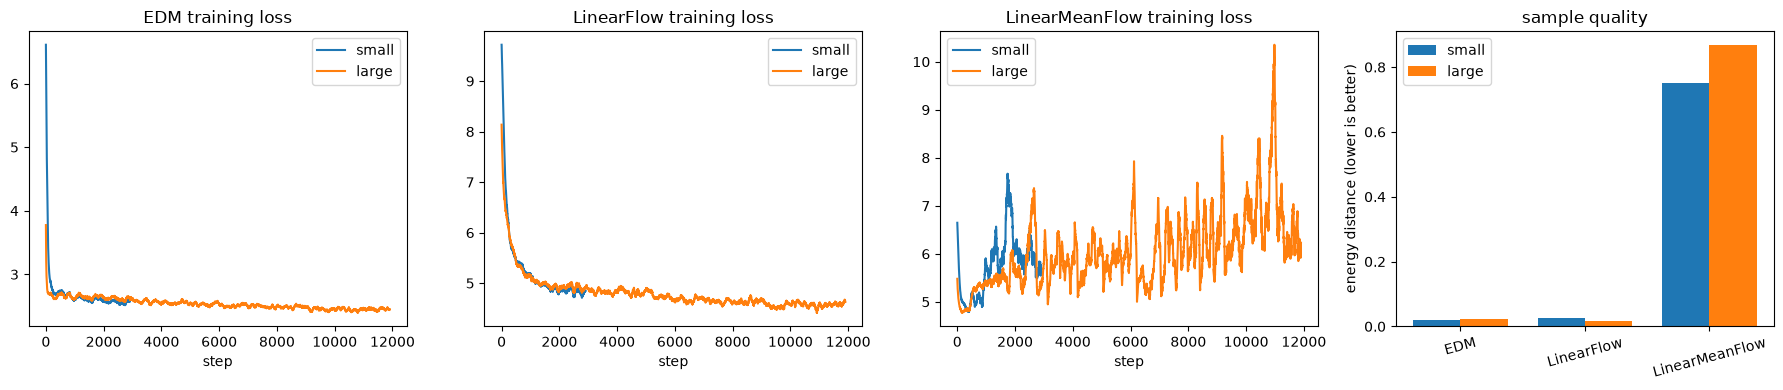

In [7]:
def smooth(values, window=100):
    kernel = jnp.ones(window) / window
    return jnp.convolve(jnp.asarray(values), kernel, mode="valid")


fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes[:3], MODELS):
    for scale_name, color in zip(SCALES, ("C0", "C1")):
        losses = results[(name, scale_name)]["losses"]
        ax.plot(smooth(losses), color=color, label=scale_name)
    ax.set_title(f"{name} training loss")
    ax.set_xlabel("step")
    ax.legend()

names = list(MODELS)
x = jnp.arange(len(names))
width = 0.38
for offset, (scale_name, color) in enumerate(zip(SCALES, ("C0", "C1"))):
    values = [results[(name, scale_name)]["energy_distance"] for name in names]
    axes[3].bar(x + (offset - 0.5) * width, values, width, color=color, label=scale_name)
axes[3].set_xticks(x, names, rotation=15)
axes[3].set_ylabel("energy distance (lower is better)")
axes[3].set_title("sample quality")
axes[3].legend()
plt.tight_layout()
plt.show()

Mean flow is trained to predict the average velocity over an interval, so a
single jump can be enough in principle. This sweep uses the larger mean-flow
model and shows the actual trade-off at this training budget: the one-jump
sampler is very fast but inaccurate, and quality reaches the ODE samplers by
roughly 8-16 steps.

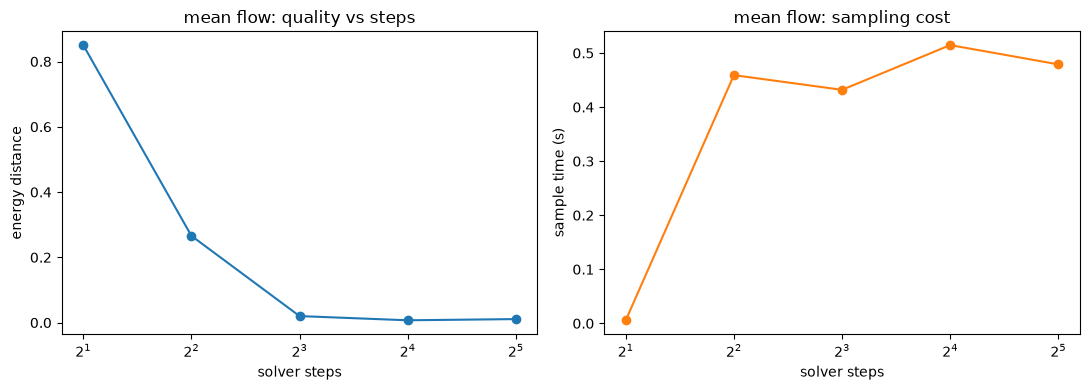

steps= 2  time=0.006s  energy distance=0.8503
steps= 4  time=0.459s  energy distance=0.2659
steps= 8  time=0.432s  energy distance=0.0200
steps=16  time=0.515s  energy distance=0.0072
steps=32  time=0.479s  energy distance=0.0108


In [8]:
mean_flow = results[("LinearMeanFlow", "large")]["model"]
step_counts = [2, 4, 8, 16, 32]
sweep = []
for num_steps in step_counts:
    start = time.perf_counter()
    samples = mean_flow.as_dist((2,), num_steps=num_steps).sample(
        jax.random.key(7), (2048,)
    )
    jax.block_until_ready(samples)
    elapsed = time.perf_counter() - start
    sweep.append((num_steps, elapsed, float(energy_distance(samples, test_data))))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
steps = [row[0] for row in sweep]
axes[0].plot(steps, [row[2] for row in sweep], "o-")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("solver steps")
axes[0].set_ylabel("energy distance")
axes[0].set_title("mean flow: quality vs steps")

axes[1].plot(steps, [row[1] for row in sweep], "o-", color="C1")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("solver steps")
axes[1].set_ylabel("sample time (s)")
axes[1].set_title("mean flow: sampling cost")
plt.tight_layout()
plt.show()

for num_steps, elapsed, distance in sweep:
    print(f"steps={num_steps:2d}  time={elapsed:.3f}s  energy distance={distance:.4f}")

- All three families learn the checkerboard with the same `fit`/`as_dist` API,
  so swapping the generative objective is a one-line change.
- `EDM` and `LinearFlow` reach low energy distance with a 32-step sampler and
  are robust to the scale change here. The one-jump mean-flow sampler is much
  faster but needs about 8-16 steps to reach the same quality at this budget.
- The energy distance is a distribution-level metric; look at the sample plots
  as well, since two models can match the metric while failing on different
  modes.
- This is a single-seed toy study. Treat the timings as wall-clock for this
  GPU and these scales, not as a general benchmark.